# LAB 7 · Filtrado adaptativo y wavelet de una señal EMG

| Campo | Completar |
|---|---|
| **Nombre del estudiante** | ______________________________ |
| **Código** | ______________________________ |
| **Fecha** | ______________________________ |

> **Enfoque:** observamos la señal muscular medida, analizamos su contenido y sus limitaciones, añadimos contaminación **sintética** controlada y comparamos varias técnicas de filtrado.

**Señal:** canal A1 de un registro OpenSignals con sensor EMGBITREV. La señal se conserva en cuentas del convertidor ADC: el archivo no contiene calibración para convertirlas a voltios. Los valores pegados a los límites ADC sugieren posible saturación; ningún filtro puede reconstruir muestras recortadas.

## Objetivos y cautelas

1. Leer el encabezado OpenSignals y verificar la frecuencia de muestreo y el canal.
2. Visualizar el registro completo, un tramo representativo, la envolvente RMS y el espectro.
3. Añadir ruido artificial reproducible para poder comparar resultados contra el tramo medido usado como referencia del experimento.
4. Comparar un pasa-banda Butterworth, un notch de 60 Hz, un cancelador LMS con referencia sinusoidal sintética y una reducción de ruido wavelet.

**Importante:** el EMG original no se etiqueta como limpio ni se dispone de una referencia fisiológica limpia. La interferencia y el ruido que se añaden son simulados, no se afirma que estuvieran en la medición. Las métricas del experimento sintético se calculan contra el tramo medido previo a la contaminación; no demuestran la calidad absoluta del EMG ni recuperan muestras saturadas.

## 1. Dependencias e imports

Si falta algún paquete, descomenta y ejecuta esta celda una vez:

In [11]:
%pip install numpy pandas matplotlib scipy PyWavelets

Note: you may need to restart the kernel to use updated packages.


In [12]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt
from scipy import signal
from IPython.display import display

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True})
np.random.seed(7)
print("Imports listos.")

Imports listos.


## 2. Carga del archivo OpenSignals

El archivo trae tres líneas de encabezado y luego seis columnas separadas por espacios o tabuladores. La última columna, **A1**, es el canal analógico de EMG. Se prueba primero el archivo adyacente a esta libreta y después la ruta original enviada.

In [13]:
candidates = [
    Path.cwd() / "Fuerte_emg.txt",
    Path(r"C:\Users\leams\Downloads\Fuerte_emg.txt"),
]
data_path = next((p for p in candidates if p.is_file()), None)
if data_path is None:
    tried = "\n".join(str(p) for p in candidates)
    raise FileNotFoundError(f"No se encontró Fuerte_emg.txt. Rutas revisadas:\n{tried}")

with data_path.open("r", encoding="utf-8-sig") as f:
    header_lines = [next(f) for _ in range(3)]
metadata_root = json.loads(header_lines[1].lstrip("# ").strip())
device_metadata = next(iter(metadata_root.values()))
fs = float(device_metadata["sampling rate"])
column_names = ["nSeq", "I1", "I2", "O1", "O2", "A1"]
df = pd.read_csv(data_path, sep=r"\s+", skiprows=3, header=None, names=column_names)

if df.shape[1] != 6 or df.empty or fs <= 0:
    raise ValueError(f"Formato o frecuencia de muestreo inválidos: shape={df.shape}, fs={fs}")
emg = df["A1"].to_numpy(dtype=float)
t = np.arange(emg.size) / fs
duration = emg.size / fs

print(f"Archivo: {data_path}")
print(f"Sensor/canal: {device_metadata['sensor'][0]} / {device_metadata['label'][0]}")
print(f"Frecuencia: {fs:g} Hz | muestras: {emg.size:,} | duración: {duration:.1f} s")
print(f"Unidades: cuentas ADC | mínimo: {emg.min():.0f} | máximo: {emg.max():.0f}")
display(df.head())

Archivo: c:\Users\leams\.copilot\session-state\551f7a56-9001-411f-9273-27356ee05256\files\Fuerte_emg.txt
Sensor/canal: EMGBITREV / A1
Frecuencia: 1000 Hz | muestras: 291,600 | duración: 291.6 s
Unidades: cuentas ADC | mínimo: 0 | máximo: 1022


,nSeq,I1,I2,O1,O2,A1
0,0,0,0,0,0,511
1,1,0,0,0,0,514
2,2,0,0,0,0,513
3,3,0,0,0,0,514
4,4,0,0,0,0,513


## 3. Inspección global y posible saturación

Para que la gráfica del registro largo sea legible, se dibuja una de cada diez muestras; los cálculos usan todas las muestras. El recorte se estima como la fracción de muestras exactamente en los extremos observados del convertidor (0 y 1022).

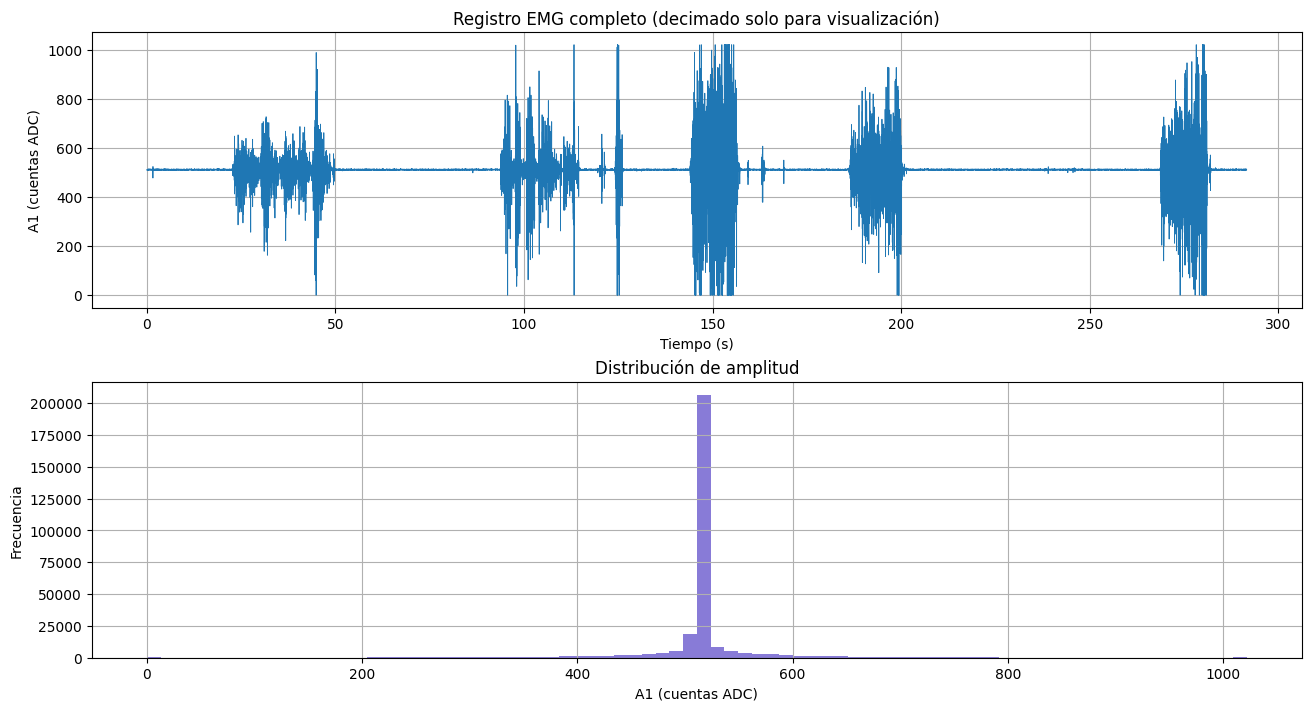

Media: 512.313 cuentas | desviación estándar: 65.667 cuentas
Muestras en los extremos 0/1022: 867 (0.297 %)
Advertencia: hay posibles muestras recortadas; el filtrado no recupera la amplitud perdida.


In [14]:
adc_low, adc_high = 0, 1022
clip_mask = (emg <= adc_low) | (emg >= adc_high)
clip_fraction = clip_mask.mean()

fig, axes = plt.subplots(2, 1, figsize=(13, 7), constrained_layout=True)
axes[0].plot(t[::10], emg[::10], lw=0.6)
axes[0].set(title="Registro EMG completo (decimado solo para visualización)",
            xlabel="Tiempo (s)", ylabel="A1 (cuentas ADC)")
axes[1].hist(emg, bins=80, color="slateblue", alpha=0.8)
axes[1].set(title="Distribución de amplitud", xlabel="A1 (cuentas ADC)", ylabel="Frecuencia")
plt.show()

print(f"Media: {emg.mean():.3f} cuentas | desviación estándar: {emg.std():.3f} cuentas")
print(f"Muestras en los extremos 0/1022: {clip_mask.sum():,} ({100 * clip_fraction:.3f} %)")
if clip_fraction:
    print("Advertencia: hay posibles muestras recortadas; el filtrado no recupera la amplitud perdida.")

## 4. Envolvente RMS y tramo de análisis

La envolvente RMS de un segundo ayuda a localizar periodos de distinta actividad. Se selecciona automáticamente una ventana de cinco segundos con mayor RMS entre ventanas completas de un segundo; esto es solo una selección práctica para visualizar y no una segmentación clínica.

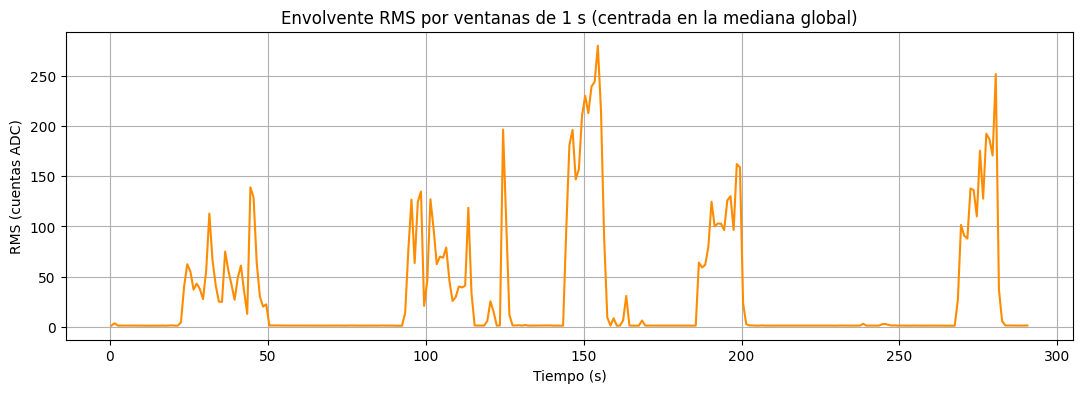

Tramo elegido: 154.0–159.0 s (5 s), centrado cerca de la mayor RMS por segundo.


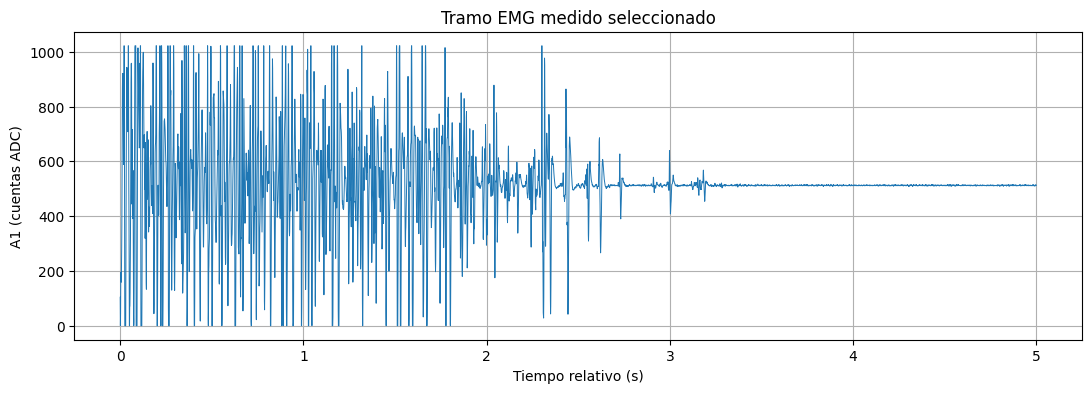

In [15]:
window = max(1, int(round(fs)))
n_windows = emg.size // window
windowed = emg[:n_windows * window].reshape(n_windows, window)
baseline = np.median(emg)
rms_1s = np.sqrt(np.mean((windowed - baseline) ** 2, axis=1))
times_1s = (np.arange(n_windows) + 0.5) * window / fs

plt.figure(figsize=(13, 4))
plt.plot(times_1s, rms_1s, color="darkorange")
plt.title("Envolvente RMS por ventanas de 1 s (centrada en la mediana global)")
plt.xlabel("Tiempo (s)")
plt.ylabel("RMS (cuentas ADC)")
plt.show()

segment_seconds = 5
segment_len = int(round(segment_seconds * fs))
best_start_s = int(np.argmax(rms_1s))
start = min(best_start_s * window, emg.size - segment_len)
stop = start + segment_len
x = emg[start:stop]
tx = np.arange(x.size) / fs
print(f"Tramo elegido: {start/fs:.1f}–{stop/fs:.1f} s (5 s), centrado cerca de la mayor RMS por segundo.")

plt.figure(figsize=(13, 4))
plt.plot(tx, x, lw=0.7)
plt.title("Tramo EMG medido seleccionado")
plt.xlabel("Tiempo relativo (s)")
plt.ylabel("A1 (cuentas ADC)")
plt.show()

## 5. Contenido espectral del EMG medido

Se estima la densidad espectral con Welch sobre el tramo seleccionado. El rango de interés depende del sensor, el protocolo y la calidad del registro. Con \(f_s=1000\) Hz, la frecuencia de Nyquist es 500 Hz; un filtro que llegue a 450 Hz deja una banda de transición estrecha y no elimina el aliasing ya presente en la adquisición.

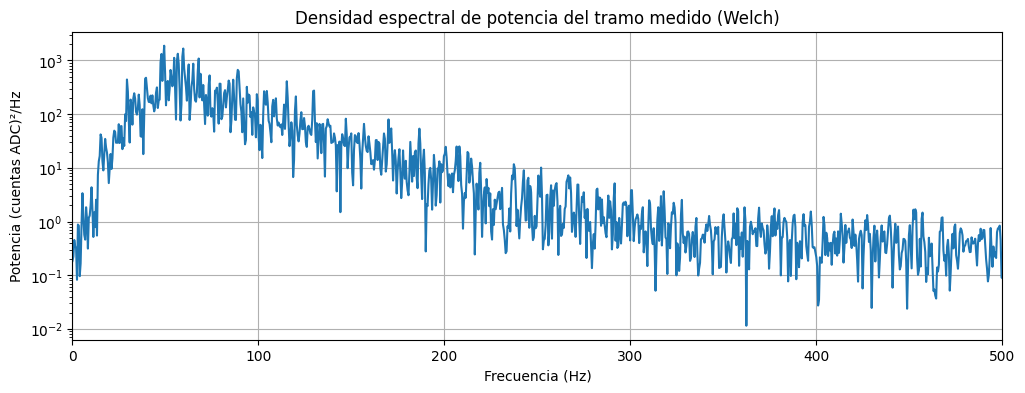

In [16]:
freq, psd = signal.welch(x, fs=fs, nperseg=min(2048, x.size))
plt.figure(figsize=(12, 4))
plt.semilogy(freq, psd)
plt.xlim(0, fs / 2)
plt.title("Densidad espectral de potencia del tramo medido (Welch)")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Potencia (cuentas ADC)²/Hz")
plt.show()

## 6. Experimento reproducible: contaminación sintética

Al tramo medido se le suma interferencia sinusoidal sintética de 60 Hz y ruido blanco gaussiano. Se fija una semilla para repetir el ejemplo. El tramo original es la **referencia medida previa a la contaminación**, no una verdad limpia del EMG.

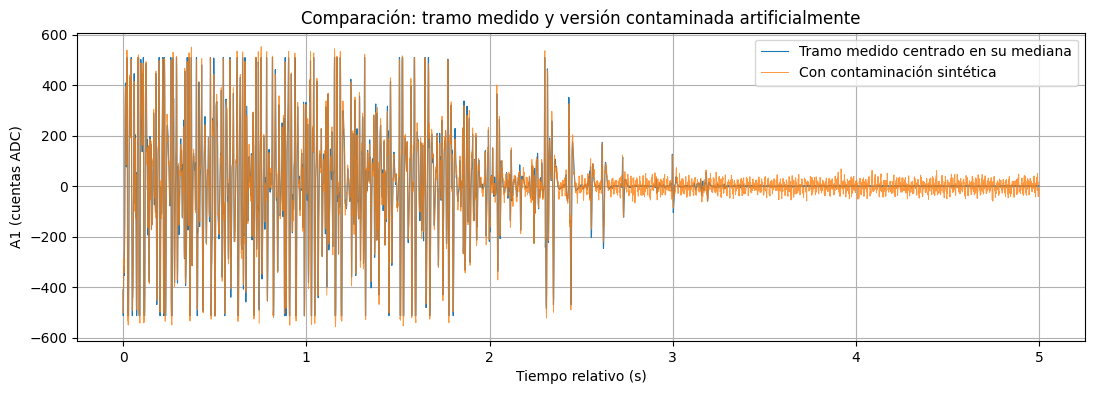

In [17]:
rng = np.random.default_rng(2026)
x_reference = x - np.median(x)
interference_hz = 60.0
white_noise_std = 15.0
interference_amplitude = 20.0
synthetic_interference = interference_amplitude * np.sin(2 * np.pi * interference_hz * tx)
synthetic_noise = rng.normal(0.0, white_noise_std, size=x.size)
x_noisy = x_reference + synthetic_interference + synthetic_noise

plt.figure(figsize=(13, 4))
plt.plot(tx, x_reference, label="Tramo medido centrado en su mediana", lw=0.8)
plt.plot(tx, x_noisy, label="Con contaminación sintética", lw=0.7, alpha=0.8)
plt.title("Comparación: tramo medido y versión contaminada artificialmente")
plt.xlabel("Tiempo relativo (s)")
plt.ylabel("A1 (cuentas ADC)")
plt.legend()
plt.show()

## 7. Filtrado del tramo sintéticamente contaminado

- **Butterworth pasa-banda 20–450 Hz:** reduce deriva lenta y componentes por encima de la banda elegida. No se aplica como criterio universal para todos los EMG.
- **Notch 60 Hz:** atenúa la componente de red configurada en esta simulación.
- **LMS adaptativo:** usa dos referencias sintéticas en cuadratura (seno y coseno de 60 Hz) para demostrar la cancelación adaptativa de una sinusoide conocida. No estima automáticamente artefactos reales del archivo.
- **Wavelet:** aplica umbral suave en coeficientes de detalle; el nivel se limita según la longitud y la wavelet escogida.

El filtrado de fase cero usa `sosfiltfilt`; cerca de los bordes puede haber efectos transitorios. El LMS es recursivo y aquí se inicializa en cero.

In [18]:
nyquist = fs / 2
if not (0 < 20 < 450 < nyquist):
    raise ValueError(f"La banda 20–450 Hz no es válida para fs={fs:g} Hz.")
sos = signal.butter(4, [20, 450], btype="bandpass", fs=fs, output="sos")
y_bandpass = signal.sosfiltfilt(sos, x_noisy)

b_notch, a_notch = signal.iirnotch(60.0, Q=30, fs=fs)
y_notch = signal.filtfilt(b_notch, a_notch, x_noisy)

def lms_cancel(reference, desired, mu=0.08):
    weights = np.zeros(reference.shape[1], dtype=float)
    output = np.empty_like(desired, dtype=float)
    for i, (sample, ref) in enumerate(zip(desired, reference)):
        estimate = np.dot(weights, ref)
        error = sample - estimate
        weights += mu * error * ref / (np.dot(ref, ref) + 1e-12)
        output[i] = error
    return output, weights

reference_60hz = np.column_stack([
    np.sin(2 * np.pi * interference_hz * tx),
    np.cos(2 * np.pi * interference_hz * tx),
])
y_lms, lms_weights = lms_cancel(reference_60hz, x_noisy)

wavelet = "db4"
max_level = pywt.dwt_max_level(x_noisy.size, pywt.Wavelet(wavelet).dec_len)
level = min(5, max_level)
if level < 1:
    raise ValueError("El tramo es demasiado corto para el nivel wavelet seleccionado.")
coeffs = pywt.wavedec(x_noisy, wavelet, mode="symmetric", level=level)
sigma = np.median(np.abs(coeffs[-1])) / 0.6745
threshold = sigma * np.sqrt(2 * np.log(x_noisy.size))
coeffs_denoised = [coeffs[0]] + [
    pywt.threshold(c, threshold, mode="soft") for c in coeffs[1:]
]
y_wavelet = pywt.waverec(coeffs_denoised, wavelet, mode="symmetric")[:x_noisy.size]

print(f"Butterworth pasa-banda: 20–450 Hz, orden 4 | LMS pesos finales: {lms_weights}")
print(f"Wavelet: {wavelet}, nivel {level}, umbral suave: {threshold:.2f} cuentas")

Butterworth pasa-banda: 20–450 Hz, orden 4 | LMS pesos finales: [22.45023581 -3.41401345]
Wavelet: db4, nivel 5, umbral suave: 83.56 cuentas


## 8. Comparación visual de filtros

Las curvas se superponen en el mismo tramo. Los filtros pueden alterar amplitud y contenido muscular; una salida visualmente más suave no implica necesariamente mayor fidelidad fisiológica.

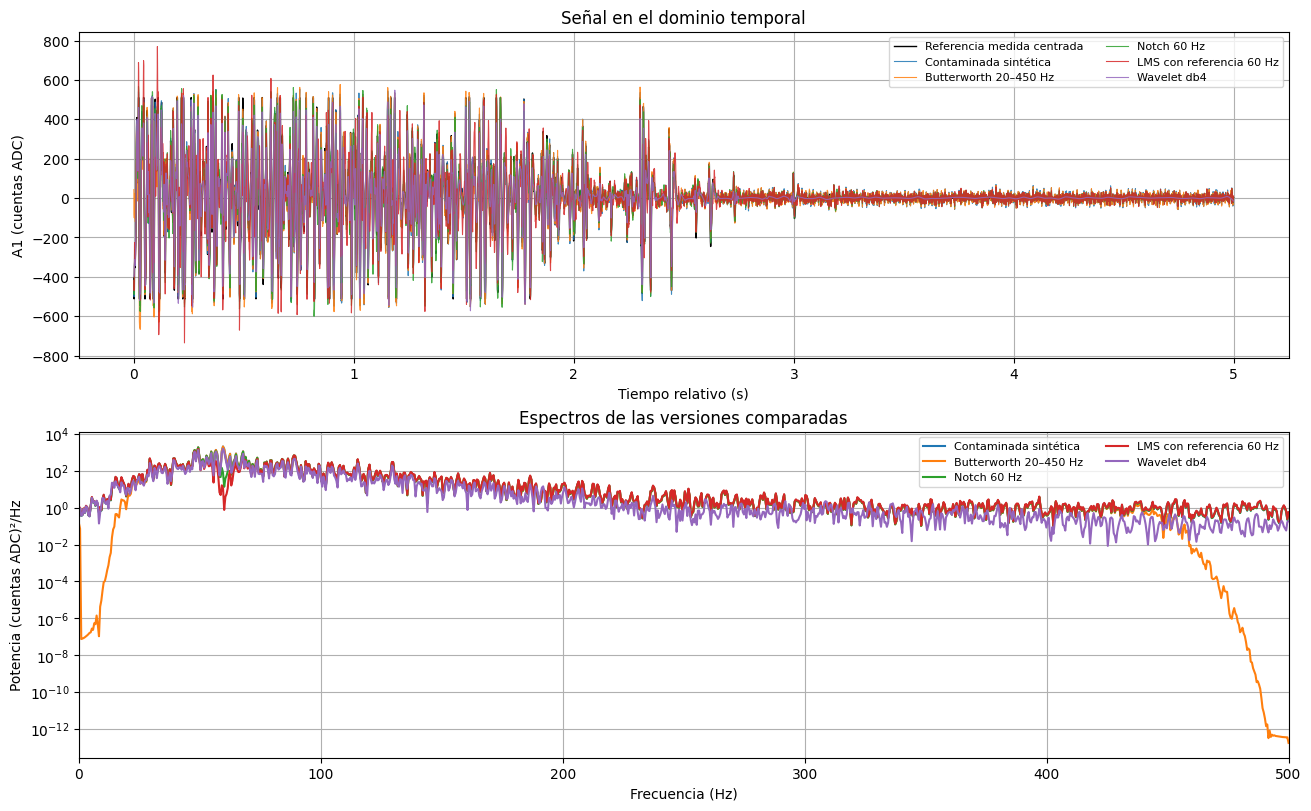

In [19]:
outputs = {
    "Contaminada sintética": x_noisy,
    "Butterworth 20–450 Hz": y_bandpass,
    "Notch 60 Hz": y_notch,
    "LMS con referencia 60 Hz": y_lms,
    "Wavelet db4": y_wavelet,
}
fig, axes = plt.subplots(2, 1, figsize=(13, 8), constrained_layout=True)
axes[0].plot(tx, x_reference, label="Referencia medida centrada", color="black", lw=1)
for label, y in outputs.items():
    axes[0].plot(tx, y, label=label, lw=0.8, alpha=0.85)
axes[0].set(title="Señal en el dominio temporal", xlabel="Tiempo relativo (s)", ylabel="A1 (cuentas ADC)")
axes[0].legend(ncol=2, fontsize=8)

for label, y in outputs.items():
    f, p = signal.welch(y, fs=fs, nperseg=min(2048, y.size))
    axes[1].semilogy(f, p, label=label)
axes[1].set(title="Espectros de las versiones comparadas", xlabel="Frecuencia (Hz)", ylabel="Potencia (cuentas ADC)²/Hz", xlim=(0, fs/2))
axes[1].legend(ncol=2, fontsize=8)
plt.show()

## 9. Métricas del experimento sintético

Se calcula RMSE y SNR respecto del tramo medido utilizado antes de sumar contaminación. Estos números comparan el resultado con esa referencia experimental concreta; no deben interpretarse como SNR del EMG fisiológico real ni como validación clínica. Los filtros alteran contenido legítimo, por eso una métrica menor no siempre equivale a una señal más útil.

In [20]:
def rmse(reference, estimate):
    return float(np.sqrt(np.mean((reference - estimate) ** 2)))

def snr_db(reference, estimate):
    error = reference - estimate
    error_power = np.mean(error ** 2)
    signal_power = np.mean((reference - np.mean(reference)) ** 2)
    return float(10 * np.log10(signal_power / max(error_power, np.finfo(float).tiny)))

comparisons = {
    "Contaminada sintética": x_noisy,
    **{k: v for k, v in outputs.items() if k != "Contaminada sintética"},
}
metric_rows = []
for label, y in comparisons.items():
    metric_rows.append({
        "Versión": label,
        "RMSE vs. referencia medida centrada (cuentas)": rmse(x_reference, y),
        "SNR relativa vs. referencia medida centrada (dB)": snr_db(x_reference, y),
    })
metrics = pd.DataFrame(metric_rows).sort_values("RMSE vs. referencia medida centrada (cuentas)")
display(metrics.round(3))

,Versión,RMSE vs. referencia medida centrada (cuentas),SNR relativa vs. referencia medida centrada (dB)
0,Contaminada sintética,20.617,17.956
1,Butterworth 20–450 Hz,28.596,15.115
2,Notch 60 Hz,33.699,13.688
4,Wavelet db4,39.350,12.342
3,LMS con referencia 60 Hz,88.143,5.337


## 10. Conclusiones para completar

- ¿Qué cambios aparecen en la envolvente y el espectro del registro EMG medido?
- En el experimento sintético, ¿qué filtro reduce mejor la interferencia de 60 Hz? Compara el espectro cerca de 60 Hz y las métricas.
- ¿Qué diferencias observas entre pasa-banda, notch, LMS y wavelet en amplitud y forma temporal?
- ¿Qué limitaciones introducen la posible saturación, la falta de calibración y la ausencia de una referencia EMG limpia?

**Conclusión técnica:** reporta los valores calculados por esta libreta; distingue claramente la observación del registro original del experimento con contaminación sintética. No interpretes muestras saturadas como amplitudes fisiológicas recuperables.

## Referencias breves

- OpenSignals (PLUX), formato de texto y metadatos del registro incluidos en el archivo.
- Oppenheim, A. V. & Schafer, R. W., *Discrete-Time Signal Processing* (muestreo y filtrado digital).
- Donoho, D. L. (1995), “De-noising by soft-thresholding”, *IEEE Transactions on Information Theory* (umbral wavelet).

---

**Nota de reproducibilidad:** la libreta se entrega junto a `Fuerte_emg.txt`; colócalos en la misma carpeta para que la ruta relativa funcione.